# Morphometric variation: simulation- and seed-conditioned generation

This notebook compares only simulation-conditioned and seed-conditioned diffusion generation for four morphometric views: terminal branch-width KDE, intra-plate terminal-width CV, total skeleton tips, and total skeleton length.

Seed-conditioned outputs use the corrected 3-left/2-right crop and include generated replicates linked to their conditioning stem or fixed seed configuration.


### Seed-count display convention (2026-11-25)

Each white native-grid pixel is one seed. Fixed counts are recomputed from those
pixels when metadata is loaded: Fixed_18 = 57 and Fixed_19 = 37. The actual
`seed_count` is retained for calculations; `seed_count_plot` uses 1–26 and a final
position 27 labelled **>26**. Means and plate-bootstrap intervals pool all plates
in that final category. Branch-tip and skeleton-length summaries connect to the >26 endpoint, which is a pooled display category.
Grayscale and exploratory seed-count colors use the same overflow mapping; colorbars omit the crowded 26 tick and label the top endpoint >26.

Plots and vector-export cells were executed on 2026-11-25 using the reviewed
per-plate/width measurements, corrected seed-count metadata and pooled >26
summaries. Image measurements and cohorts were preserved. The vector PDFs and
companion plate/width/group-summary CSVs have been refreshed. Run each vector
export cell immediately after its preceding plot when regenerating figures.


In [2]:
import json
import os
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
from matplotlib import font_manager as fm
from matplotlib.colors import ListedColormap
import matplotlib.ticker as ticker
import numpy as np
import pandas as pd
from IPython.display import display
from scipy.ndimage import distance_transform_edt

from cldm.config import (
    DIFFUSION_FOLDER_TEST_FIXED, EXP_FOLDER_TEST, EXP_FOLDER_TEST_FIXED,
    FPATH, MAIN_FOLDER, PRED_FOLDER_SEEDTOEXP_CORRECTED_96,
    SEED_CONDITIONED_FOLDER_TEST_FIXED,
    SEED_FOLDER_TEST_SEEDINFO_COMBINED, SIM_FOLDER_TEST,
    SIM_FOLDER_TEST_FIXED_OUTPUT, SIM_FOLDER_TEST_FIXED_INPUT,
)
from cldm.display import create_skeleton_overlay
from cldm.morpho_features import (
    SkeletonConfig, endpoint_pixel_map, skeletonize_colony, summarize_skeleton,
)
from cldm.preprocess import (
    preprocess_experimental_backgroundblack,
    preprocess_experimental_backgroundblack_blackandwhite,
    preprocess_experimental_backgroundblack_blackandwhite_nocropping,
    preprocess_simulation,
)

fm.fontManager.addfont(str(FPATH))
plt.rcParams['font.family'] = fm.FontProperties(fname=str(FPATH)).get_name()

from cldm.seed_counts import (
    load_seed_counts, add_seed_count_plot_columns, seed_count_positions,
    seed_count_label, summarize_seed_count_groups, plot_seed_count_summary,
    configure_seed_count_axis, configure_seed_count_colorbar,
)


In [3]:
# ======================== TUNABLE PARAMETERS ========================
PLOT_FONT_SIZE = 50
plt.rcParams.update({
    'font.size': PLOT_FONT_SIZE,
    'axes.labelsize': PLOT_FONT_SIZE,
    'axes.titlesize': PLOT_FONT_SIZE,
    'xtick.labelsize': PLOT_FONT_SIZE,
    'ytick.labelsize': PLOT_FONT_SIZE,
    'legend.fontsize': PLOT_FONT_SIZE,
    'figure.dpi': 130,
    'savefig.dpi': 600,
})
SKELETON_CONFIG = SkeletonConfig(
    mask_smooth_sigma=1.25, mask_smooth_threshold=0.50,
    mask_min_object_px=64, mask_closing_radius_px=0,
    spur_factor=1.0, spur_min_px=2.0, radius_cap_px=8.0,
    max_prune_fraction=0.02, min_branches_for_pruning=5,
    blob_radius_factor=1.5, blob_min_radius_px=6.0,
    blob_min_core_area_px=50, blob_core_expansion_px=5,
    blob_interface_tolerance_px=4, blob_attachment_cluster_radius_px=2,
    blob_max_attachments=24, blob_min_attachments_for_hub=2,
    blob_path_cost_power=1.5, strand_radius_quantile=0.85,
)
TERMINAL_INSET_PX = 5.0
SIMULATION_THRESHOLD = 110
SIMULATION_BLUR_KERNEL = 5
PIXEL_SIZE = 10 / 25.92
PHYSICAL_UNIT = 'mm'

# Corrected 3-left/2-right predictions for the original and fixed test cohorts.
SEED_CONDITIONED_FOLDERS = [
    Path(PRED_FOLDER_SEEDTOEXP_CORRECTED_96),
    Path(SEED_CONDITIONED_FOLDER_TEST_FIXED),
]
SEED_CONDITIONED_SAMPLES = (1, 2)
SIM_CONDITIONED_FIXED_SAMPLE_INDEX = 1

KDE_BANDWIDTH_PX = 1.0
KDE_GRID_POINTS = 300
BOOTSTRAP_REPEATS = 1000
CONFIDENCE_LEVEL = 0.95
RANDOM_SEED = 42
EXCLUDE_DUPLICATE_SIMULATIONS = True
MAX_PLATES_PER_SOURCE = None  # set to a small integer for a quick check
FIGURE_OUTPUT_DIR = None      # e.g. 'outputs/morphometrics_seed_conditioned'
TABLE_OUTPUT_DIR = None       # e.g. 'outputs/morphometrics_seed_conditioned'
# ===================================================================

## Metric definitions

Tips are final-skeleton pixels with one 8-connected neighbor. Total skeleton length is the sum of Skan path lengths, including diagonal step lengths. Terminal width is twice the foreground distance-transform radius at the first skeleton location at least 5 pixels inward from a tip. Width CV is the sample SD divided by the mean of valid terminal widths within one plate.

In [73]:
def total_skeleton_length_px(skeleton):
    _, branch_table = summarize_skeleton(skeleton)
    return float(branch_table['branch_distance'].sum())


def path_distance(coordinates):
    steps = np.diff(coordinates.astype(float), axis=0)
    return np.r_[0.0, np.cumsum(np.linalg.norm(steps, axis=1))]


def terminal_paths(skeleton_result):
    skeleton = skeleton_result['final']
    endpoint_map = endpoint_pixel_map(skeleton)
    skan_skeleton, branch_table = summarize_skeleton(skeleton)
    paths = []
    for branch_index in range(len(branch_table)):
        coordinates = skan_skeleton.path_coordinates(branch_index).astype(int)
        if endpoint_map[tuple(coordinates[0])]:
            paths.append(coordinates)
        if endpoint_map[tuple(coordinates[-1])]:
            paths.append(coordinates[::-1])
    return paths


def terminal_widths(skeleton_result):
    distance_map = distance_transform_edt(skeleton_result['mask'])
    records = []
    for tip_index, coordinates in enumerate(terminal_paths(skeleton_result)):
        inward_distance = path_distance(coordinates)
        if inward_distance[-1] < TERMINAL_INSET_PX:
            continue
        measurement_index = np.searchsorted(inward_distance, TERMINAL_INSET_PX)
        tip = coordinates[0]
        measurement = coordinates[measurement_index]
        records.append({
            'tip_index': tip_index, 'tip_y': int(tip[0]), 'tip_x': int(tip[1]),
            'measurement_y': int(measurement[0]),
            'measurement_x': int(measurement[1]),
            'width_px': float(2 * distance_map[tuple(measurement)]),
        })
    return pd.DataFrame(records, columns=[
        'tip_index', 'tip_y', 'tip_x', 'measurement_y', 'measurement_x', 'width_px'
    ])


def image_metrics(binary_mask):
    binary_mask = np.asarray(binary_mask, dtype=bool)
    skeleton_result = skeletonize_colony(binary_mask, config=SKELETON_CONFIG)
    widths = terminal_widths(skeleton_result)
    values = widths['width_px'].to_numpy(float)
    mean_width = values.mean() if len(values) else np.nan
    sd_width = values.std(ddof=1) if len(values) > 1 else np.nan
    metrics = {
        'branch_tip_count': int(endpoint_pixel_map(skeleton_result['final']).sum()),
        'total_skeleton_length_px': total_skeleton_length_px(skeleton_result['final']),
        'valid_width_count': len(values),
        'mean_terminal_width_px': mean_width,
        'sd_terminal_width_px': sd_width,
        'median_terminal_width_px': np.median(values) if len(values) else np.nan,
        'width_iqr_px': (np.percentile(values, 75) - np.percentile(values, 25))
                        if len(values) else np.nan,
        'width_cv': sd_width / mean_width if len(values) > 1 and mean_width > 0 else np.nan,
    }
    return metrics, skeleton_result, widths

## Resolve a matched simulation- and seed-conditioned cohort

The analysis includes only stems with both simulation-conditioned and seed-conditioned outputs, plus seed-count metadata required for grouping the plots.


In [4]:
def stem_sort_key(stem):
    parts = stem.split('_')
    return (parts[0] == 'Fixed', tuple(int(value) for value in parts if value.isdigit()))


def files_by_stem(folder, extensions):
    folder = Path(folder)
    return {path.stem: path for path in folder.iterdir()
            if path.is_file() and path.suffix.lower() in extensions}


experimental_paths = {}
for folder in (EXP_FOLDER_TEST, EXP_FOLDER_TEST_FIXED):
    experimental_paths.update(files_by_stem(folder, {'.tif', '.tiff'}))

simulation_paths = files_by_stem(SIM_FOLDER_TEST, {'.tif', '.tiff'})
fixed_simulations = files_by_stem(SIM_FOLDER_TEST_FIXED_OUTPUT, {'.png'})
for stem in experimental_paths:
    if stem.startswith('Fixed_'):
        candidate = fixed_simulations.get(f"Output_Fixed_{stem.split('_')[1]}")
        if candidate is not None:
            simulation_paths[stem] = candidate

sim_conditioned_paths = files_by_stem(MAIN_FOLDER, {'.png'})
for path in Path(DIFFUSION_FOLDER_TEST_FIXED).glob(
        f'*_{SIM_CONDITIONED_FIXED_SAMPLE_INDEX}.png'):
    stem = path.stem.rsplit('_', 1)[0]
    sim_conditioned_paths[stem] = path

original_seed_conditioned_raw = (
    files_by_stem(SEED_CONDITIONED_FOLDERS[0], {'.png'})
    if SEED_CONDITIONED_FOLDERS[0].is_dir() else {}
)
fixed_seed_conditioned_raw = (
    files_by_stem(SEED_CONDITIONED_FOLDERS[1], {'.png'})
    if SEED_CONDITIONED_FOLDERS[1].is_dir() else {}
)

# One analysis item per generated plate. The metadata stem links each generated
# replicate to its conditioning stem/configuration and therefore its seed count.
seed_conditioned_items = []
seed_conditioned_coverage = set()
for stem in sorted((s for s in experimental_paths if not s.startswith('Fixed_')),
                   key=stem_sort_key):
    paths = [original_seed_conditioned_raw.get(f'{stem}_{sample}')
             for sample in SEED_CONDITIONED_SAMPLES]
    if all(path is not None for path in paths):
        seed_conditioned_coverage.add(stem)
        seed_conditioned_items.extend([
            (f'{stem}__generated_{sample}', stem, path)
            for sample, path in zip(SEED_CONDITIONED_SAMPLES, paths)
        ])

fixed_configuration_stems = sorted(
    {stem.rsplit('_', 1)[0] for stem in experimental_paths if stem.startswith('Fixed_')},
    key=stem_sort_key,
)
for configuration_stem in fixed_configuration_stems:
    paths = [fixed_seed_conditioned_raw.get(f'{configuration_stem}_{sample}')
             for sample in SEED_CONDITIONED_SAMPLES]
    experiment_stems = sorted(
        [stem for stem in experimental_paths if stem.rsplit('_', 1)[0] == configuration_stem],
        key=stem_sort_key,
    )
    if all(path is not None for path in paths) and experiment_stems:
        seed_conditioned_coverage.update(experiment_stems)
        metadata_stem = experiment_stems[0]
        seed_conditioned_items.extend([
            (f'{configuration_stem}__generated_{sample}', metadata_stem, path)
            for sample, path in zip(SEED_CONDITIONED_SAMPLES, paths)
        ])

seed_counts_raw = load_seed_counts(
    SEED_FOLDER_TEST_SEEDINFO_COMBINED, SIM_FOLDER_TEST_FIXED_INPUT
)
seed_counts = {Path(name).stem: count for name, count in seed_counts_raw.items()}

available = {
    'Simulation-conditioned diffusion': set(sim_conditioned_paths),
    'Seed-conditioned diffusion': seed_conditioned_coverage,
    'Seed-count metadata': set(seed_counts),
}
matched_stems = sorted(set.intersection(*available.values()), key=stem_sort_key)
availability_df = pd.DataFrame([
    {'source': source, 'available_stems': len(stems),
     'matched_stems': len(set(matched_stems) & stems)}
    for source, stems in available.items()
])
display(availability_df)
print(f'{len(matched_stems)} strictly matched stems will be analyzed')
assert matched_stems, 'No matched simulation- and seed-conditioned stems were found; check the configured folders.'

,source,available_stems,matched_stems
0,Simulation-conditioned diffusion,132,132
1,Seed-conditioned diffusion,132,132
2,Seed-count metadata,132,132


132 strictly matched stems will be analyzed


In [6]:
def load_experimental(stem):
    path = experimental_paths[stem]
    image = preprocess_experimental_backgroundblack(str(path))
    mask = preprocess_experimental_backgroundblack_blackandwhite(str(path))
    return image, mask


def load_generated(path):
    image_bgr = cv2.imread(str(path), cv2.IMREAD_COLOR)
    if image_bgr is None:
        raise FileNotFoundError(f'Could not read generated image: {path}')
    image = cv2.cvtColor(image_bgr, cv2.COLOR_BGR2RGB)
    mask = preprocess_experimental_backgroundblack_blackandwhite_nocropping(str(path))
    return image, mask


def load_simulation(stem):
    grayscale = preprocess_simulation(str(simulation_paths[stem]))
    blurred = cv2.GaussianBlur(
        grayscale, (SIMULATION_BLUR_KERNEL, SIMULATION_BLUR_KERNEL), 0
    )
    mask = blurred > SIMULATION_THRESHOLD
    return mask.astype(np.uint8) * 255, mask


loaders = {
    'Simulation': load_simulation,
    'Experiment': load_experimental,
    'Simulation-conditioned diffusion': lambda stem: load_generated(sim_conditioned_paths[stem]),
}
SOURCE_ORDER = ['Simulation-conditioned diffusion', 'Seed-conditioned diffusion']
SOURCE_COLORS = {
    'Simulation-conditioned diffusion': '#1AA3D6',
    'Seed-conditioned diffusion': '#70C7E4',
}
SOURCE_MARKERS = {
    'Simulation-conditioned diffusion': 's',
    'Seed-conditioned diffusion': 'D',
}
SOURCE_LABELS = {
    'Simulation-conditioned diffusion': 'Simulation-conditioned diffusion',
    'Seed-conditioned diffusion': 'Seed-conditioned diffusion',
}
SOURCE_TICK_LABELS = [
    SOURCE_LABELS[source].replace('-conditioned ', '-\nconditioned\n')
    for source in SOURCE_ORDER
]


## Measure every matched plate

Each source is processed with the same skeleton settings. Exact duplicate simulation replicates are excluded from simulation aggregates, as in the original notebook; the generated and experimental replicates remain separate plates.

In [ ]:
plate_records = []
width_tables = []
previous_simulation_masks = {}
selected_stems = matched_stems[:MAX_PLATES_PER_SOURCE]

for source in SOURCE_ORDER:
    if source == 'Seed-conditioned diffusion':
        source_items = [item for item in seed_conditioned_items if item[1] in set(selected_stems)]
        source_items = source_items[:MAX_PLATES_PER_SOURCE]
    else:
        source_items = [(stem, stem, None) for stem in selected_stems]
    for image_number, (image_id, stem, generated_path) in enumerate(source_items, start=1):
        if image_number % 10 == 0 or image_number == len(source_items):
            print(f'{source}: processed {image_number}/{len(source_items)} files')
        if source == 'Seed-conditioned diffusion':
            image, mask = load_generated(generated_path)
        else:
            image, mask = loaders[source](stem)
        if source == 'Simulation' and EXCLUDE_DUPLICATE_SIMULATIONS:
            prefix = stem.rsplit('_', 1)[0]
            earlier_masks = previous_simulation_masks.setdefault(prefix, [])
            if any(np.array_equal(mask, previous) for previous in earlier_masks):
                continue
            earlier_masks.append(np.asarray(mask).copy())
        metrics, skeleton_result, widths = image_metrics(mask)
        plate_records.append({
            'source': source, 'image_id': image_id, 'conditioning_stem': stem,
            'seed_count': seed_counts[stem], **metrics,
        })
        if len(widths):
            width_tables.append(widths.assign(
                source=source, image_id=image_id, conditioning_stem=stem,
                seed_count=seed_counts[stem]
            ))

plate_df = pd.DataFrame(plate_records)
terminal_width_df = pd.concat(width_tables, ignore_index=True)
add_seed_count_plot_columns(plate_df)
add_seed_count_plot_columns(terminal_width_df)
LENGTH_SCALE = PIXEL_SIZE if PIXEL_SIZE is not None else 1.0
LENGTH_UNIT = PHYSICAL_UNIT if PIXEL_SIZE is not None else 'px'
plate_df['total_skeleton_length_plot'] = plate_df['total_skeleton_length_px'] * LENGTH_SCALE
plate_df['median_terminal_width_plot'] = plate_df['median_terminal_width_px'] * LENGTH_SCALE
terminal_width_df['width_plot'] = terminal_width_df['width_px'] * LENGTH_SCALE
display(plate_df.groupby('source').agg(
    plate_count=('image_id', 'count'),
    mean_tips=('branch_tip_count', 'mean'),
    mean_skeleton_length=('total_skeleton_length_plot', 'mean'),
    mean_width_cv=('width_cv', 'mean'),
).reindex(SOURCE_ORDER))

In [7]:
def bootstrap_mean_interval(values):
    values = np.asarray(values, dtype=float)
    if len(values) == 0:
        return np.array([np.nan, np.nan])
    rng = np.random.default_rng(RANDOM_SEED)
    indices = rng.integers(0, len(values), size=(BOOTSTRAP_REPEATS, len(values)))
    bootstrap_means = values[indices].mean(axis=1)
    tail = (1 - CONFIDENCE_LEVEL) / 2
    return np.quantile(bootstrap_means, [tail, 1 - tail], axis=0)


def save_figure(fig, name):
    if FIGURE_OUTPUT_DIR is not None:
        directory = Path(FIGURE_OUTPUT_DIR)
        directory.mkdir(parents=True, exist_ok=True)
        fig.savefig(directory / f'{name}.png', dpi=300, bbox_inches='tight')
        fig.savefig(directory / f'{name}.pdf', bbox_inches='tight')


def seed_count_summary(column):
    return summarize_seed_count_groups(
        plate_df, column, SOURCE_ORDER, bootstrap_mean_interval
    )


## Terminal branch-width KDE

Thin colored curves show individual plates; thicker curves show equal-weight means of plate KDEs, with shaded intervals bootstrapped across plates. Reflection at zero prevents density from being assigned to negative widths.


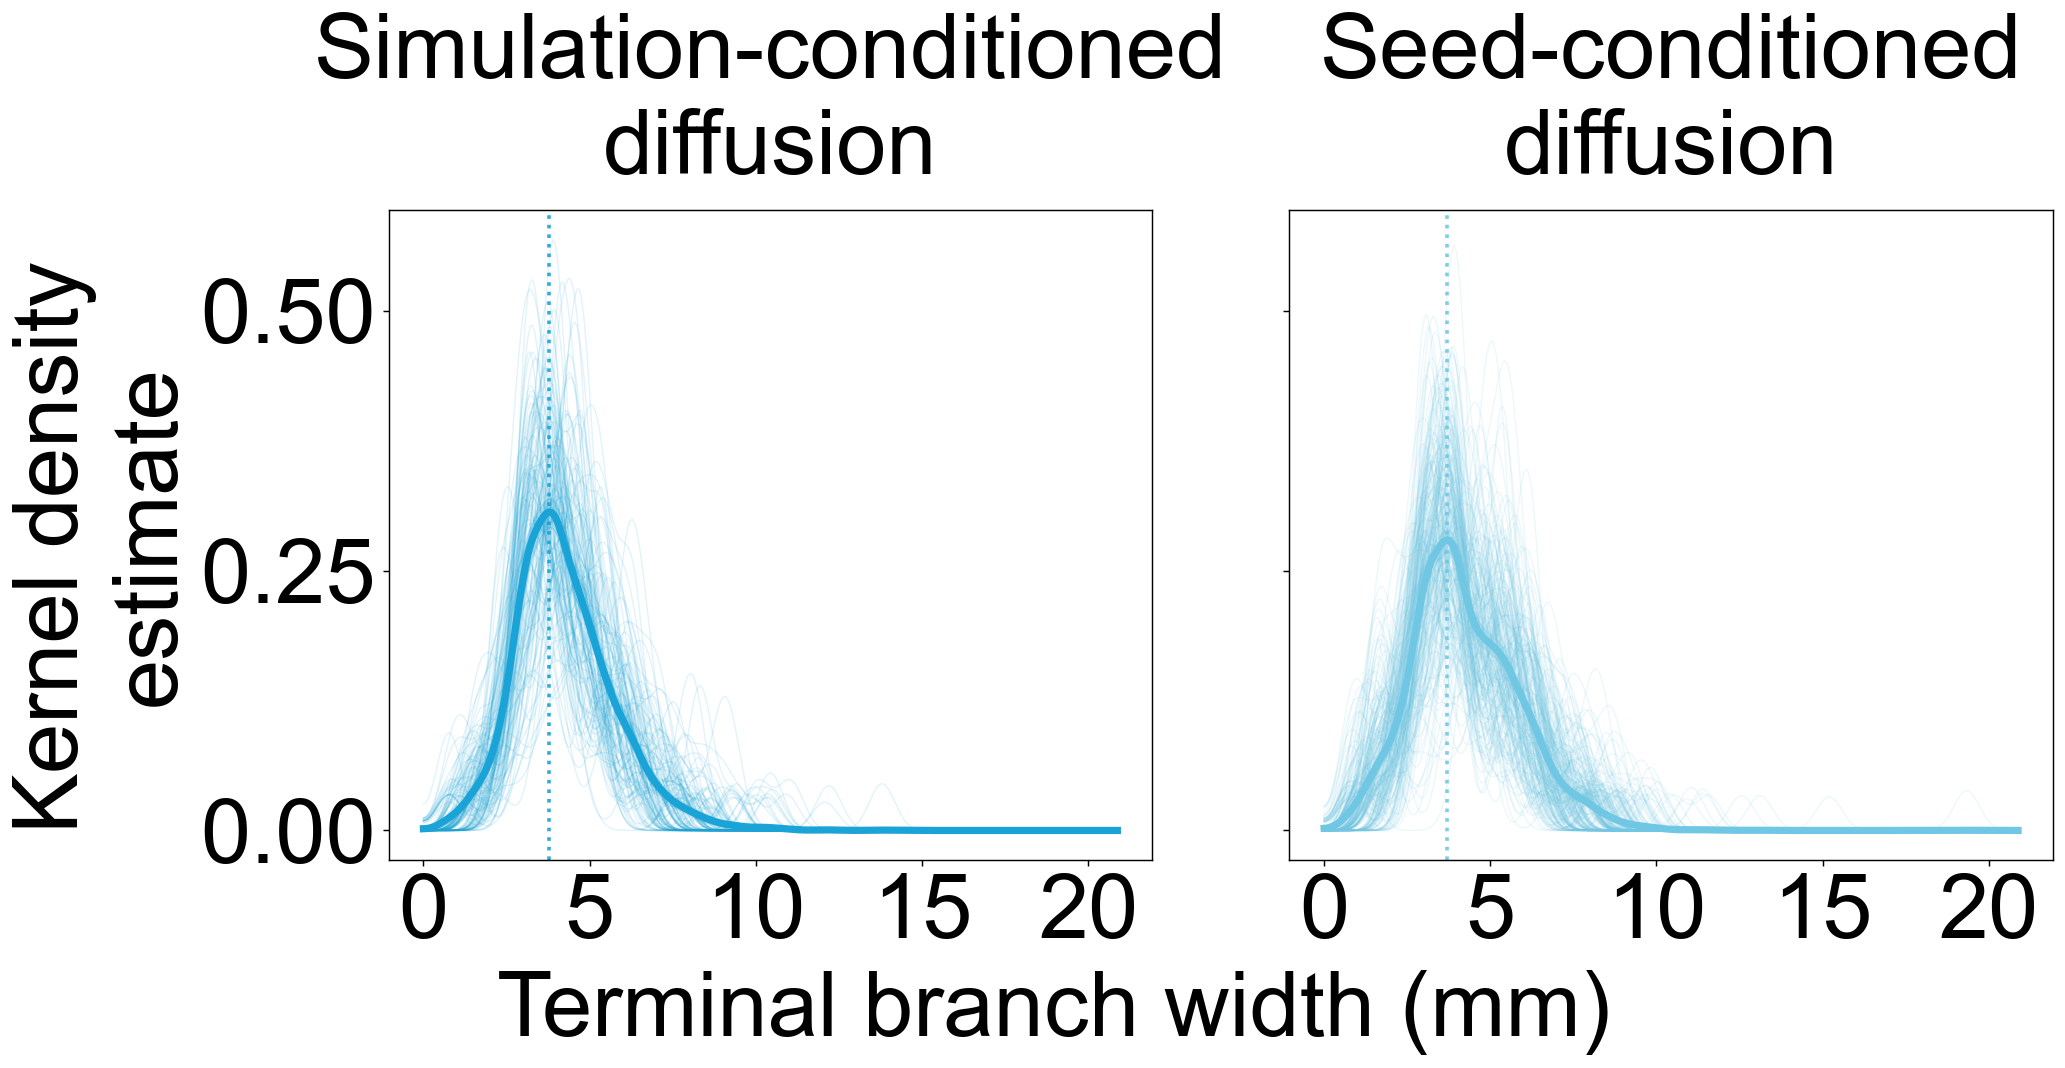

In [8]:
bandwidth = KDE_BANDWIDTH_PX * LENGTH_SCALE
maximum_width = terminal_width_df['width_plot'].max()
width_grid = np.linspace(0, maximum_width + 4 * bandwidth, KDE_GRID_POINTS)
fig, axes = plt.subplots(1, 2, figsize=(16, 10), sharex=True, sharey=True)
distribution_records = []
for ax, source in zip(axes, SOURCE_ORDER):
    densities = []
    source_widths = terminal_width_df[terminal_width_df['source'] == source]
    for stem, terminals in source_widths.groupby('image_id'):
        values = terminals['width_plot'].to_numpy(float)
        distance = (width_grid[:, None] - values[None, :]) / bandwidth
        reflected = (width_grid[:, None] + values[None, :]) / bandwidth
        density = (np.exp(-distance**2 / 2) + np.exp(-reflected**2 / 2)).mean(axis=1)
        density /= np.sqrt(2 * np.pi) * bandwidth
        ax.plot(width_grid, density, color=SOURCE_COLORS[source], lw=0.8, alpha=0.12)
        densities.append(density)
    curves = np.asarray(densities)
    lower, upper = bootstrap_mean_interval(curves)
    average = curves.mean(axis=0)
    peak_width = width_grid[int(np.nanargmax(average))]
    ax.fill_between(width_grid, lower, upper, color=SOURCE_COLORS[source], alpha=0.20)
    ax.plot(width_grid, average, color=SOURCE_COLORS[source], lw=4)
    ax.axvline(peak_width, color=SOURCE_COLORS[source], linestyle=':', lw=2, alpha=0.9)
    ax.set_title(SOURCE_LABELS[source].replace('-conditioned ', '-conditioned\n'), fontsize=PLOT_FONT_SIZE, pad=20)
    ax.xaxis.set_major_locator(ticker.MultipleLocator(5))
    distribution_records.append(pd.DataFrame({
        'source': source, f'width_{LENGTH_UNIT}': width_grid,
        'mean_density': average, 'ci_lower': lower, 'ci_upper': upper,
        'peak_width': peak_width,
    }))
axes[0].set_ylabel('Kernel density \nestimate')
fig.supxlabel(f'Terminal branch width ({LENGTH_UNIT})', fontsize=PLOT_FONT_SIZE, y=0.15)
fig.subplots_adjust(left=0.18, right=0.98, top=0.80, bottom=0.30, wspace=0.18)
save_figure(fig, 'terminal_width_kde_simulation_vs_seed_conditioned')
plt.show()
width_distribution_df = pd.concat(distribution_records, ignore_index=True)


In [9]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 18B — conditioning-source width KDEs
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig18B_conditioning_width_distributions.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_conditioning_width_distributions.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_conditioning_width_distributions.pdf')

In [10]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: current Supp. Fig. 18B individual KDE plots
from pathlib import Path
import runpy as _pdf_runpy
import matplotlib.pyplot as plt
PDF_PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'figure_exports').is_dir())
_pdf_helpers = vars(_figure_exports)
_pdf_helpers['save_conditioning_kde_panels'](fig, axes,
    PDF_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots',
    f'Terminal branch width ({LENGTH_UNIT})')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_simulation_conditioned_individual.pdf


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_seed_conditioned_individual.pdf


[PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_simulation_conditioned_individual.pdf'),
 PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18B_seed_conditioned_individual.pdf')]

## Intra-plate terminal-width CV


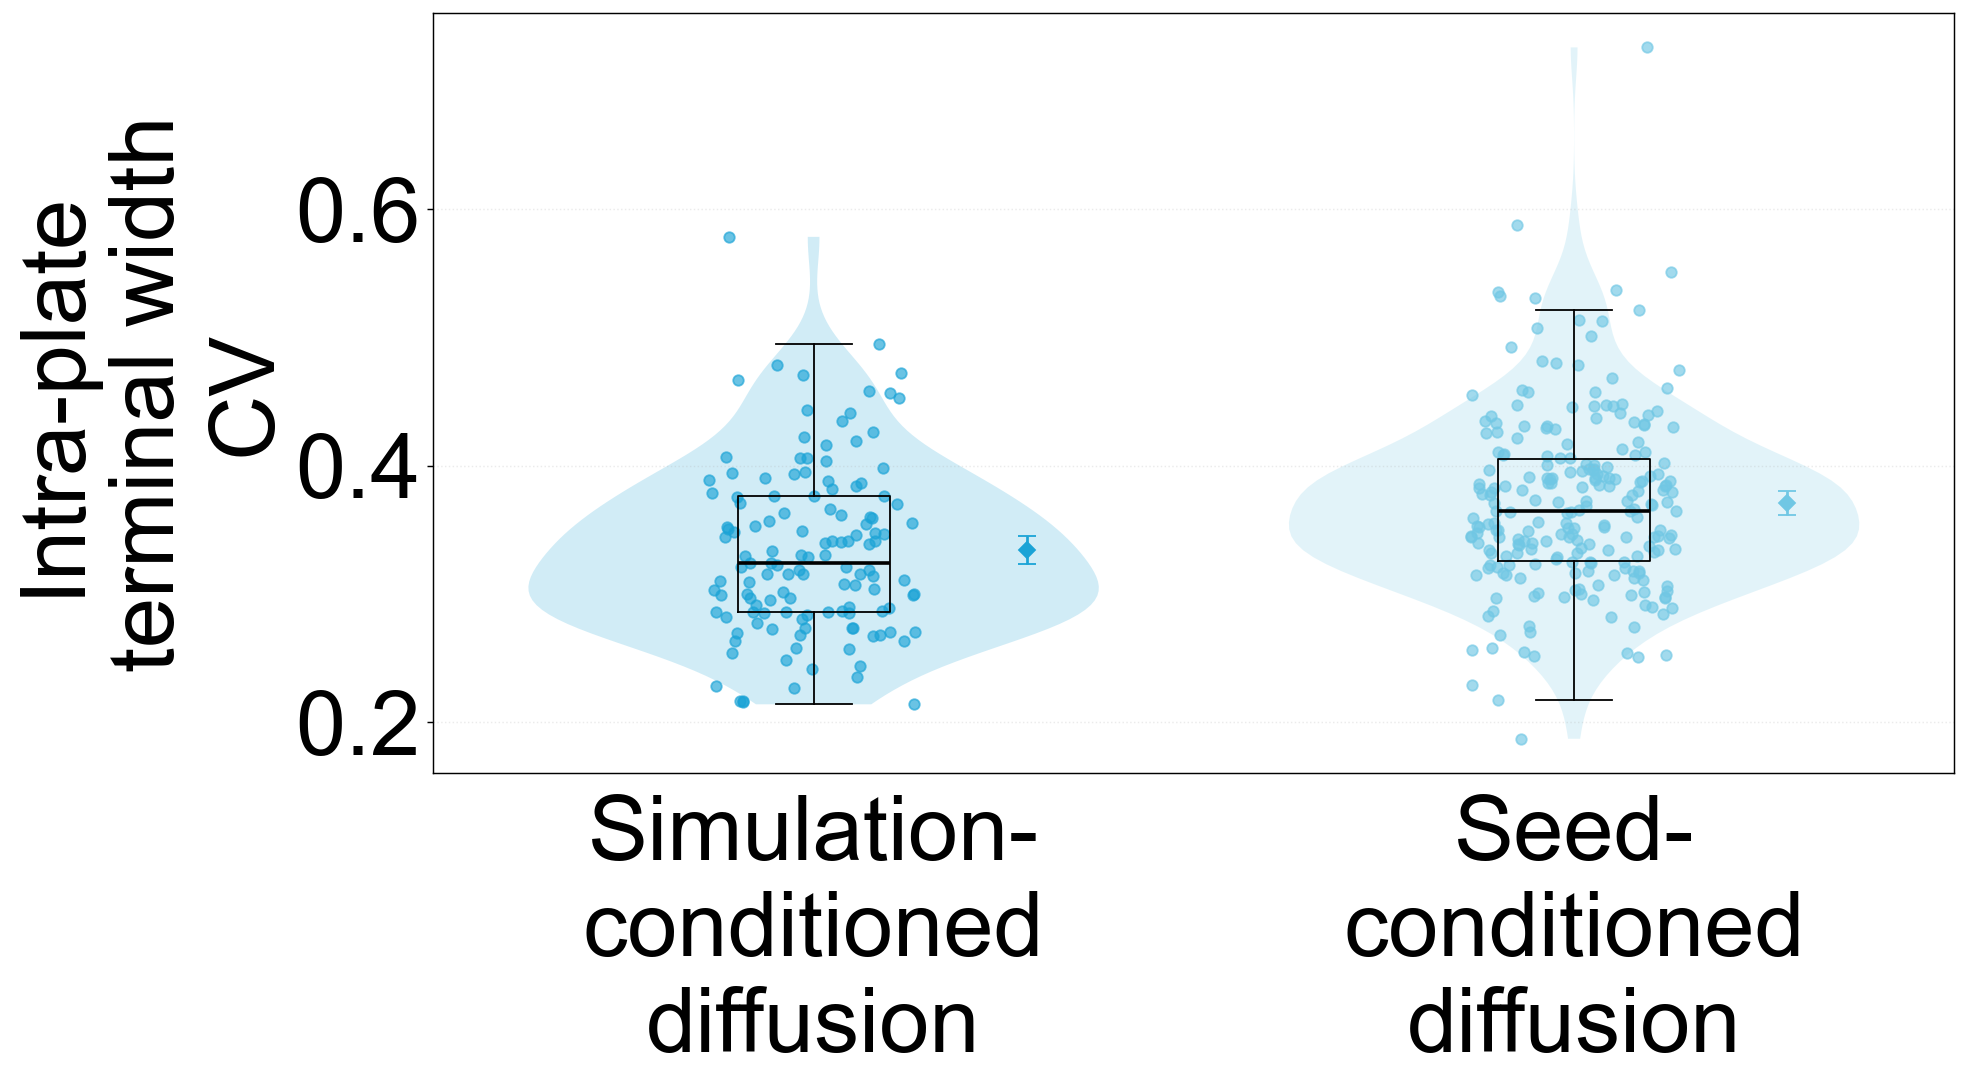

,source,plate_count,mean,ci_lower,ci_upper
0,Simulation-conditioned diffusion,132,0.334132,0.323376,0.345406
1,Seed-conditioned diffusion,230,0.370902,0.361555,0.380182


In [11]:
fig, ax = plt.subplots(figsize=(15,9))
rng = np.random.default_rng(RANDOM_SEED)
variation_records = []
for position, source in enumerate(SOURCE_ORDER):
    values = plate_df.loc[plate_df['source'] == source, 'width_cv'].dropna().to_numpy(float)
    if len(values) > 1 and np.ptp(values) > 0:
        violin = ax.violinplot(values, positions=[position], widths=0.75, showextrema=False)
        violin['bodies'][0].set_facecolor(SOURCE_COLORS[source])
        violin['bodies'][0].set_alpha(0.20)
    ax.boxplot(values, positions=[position], widths=0.20, showfliers=False,
               medianprops={'color': 'black', 'linewidth': 2})
    ax.scatter(position + rng.uniform(-0.14, 0.14, len(values)), values,
               s=34, color=SOURCE_COLORS[source], alpha=0.65)
    lower, upper = bootstrap_mean_interval(values)
    mean = values.mean()
    ax.errorbar(position + 0.28, mean, yerr=[[mean-lower], [upper-mean]],
                fmt='D', color=SOURCE_COLORS[source], capsize=5)
    variation_records.append({'source': source, 'plate_count': len(values),
                              'mean': mean, 'ci_lower': lower, 'ci_upper': upper})
ax.set_xticks(range(len(SOURCE_ORDER)), SOURCE_TICK_LABELS, fontsize=PLOT_FONT_SIZE)
ax.tick_params(axis='x', length=0, pad=12)
ax.set_ylabel('Intra-plate\nterminal width\nCV')
ax.grid(axis='y', linestyle=':', alpha=0.25)
fig.subplots_adjust(left=0.20, right=0.98, top=0.95, bottom=0.30)
save_figure(fig, 'intra_plate_width_cv_simulation_vs_seed_conditioned')
plt.show()
width_cv_summary_df = pd.DataFrame(variation_records)
display(width_cv_summary_df)


In [12]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: Supp. Fig. 18C — conditioning-source width CV
# Run immediately after the preceding plotting/analysis cell.
from pathlib import Path
import runpy as _vector_runpy

# Locate the project from the notebook working directory; no sys.path changes.
VECTOR_PROJECT_ROOT = next(
    _p for _p in (Path.cwd(), *Path.cwd().parents)
    if (_p / 'figure_exports').is_dir()
)
save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
VECTOR_DIR = VECTOR_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots'

save_vector_pdf(fig, VECTOR_DIR / 'SuppFig18C_conditioning_width_cv.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18C_conditioning_width_cv.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18C_conditioning_width_cv.pdf')

## Total skeleton tips versus initial seed count


The final **>26** category pools the 37- and 57-seed configurations; actual counts are retained separately.

The >26 mean/error-bar marker is connected to the preceding numeric group as a visual guide.

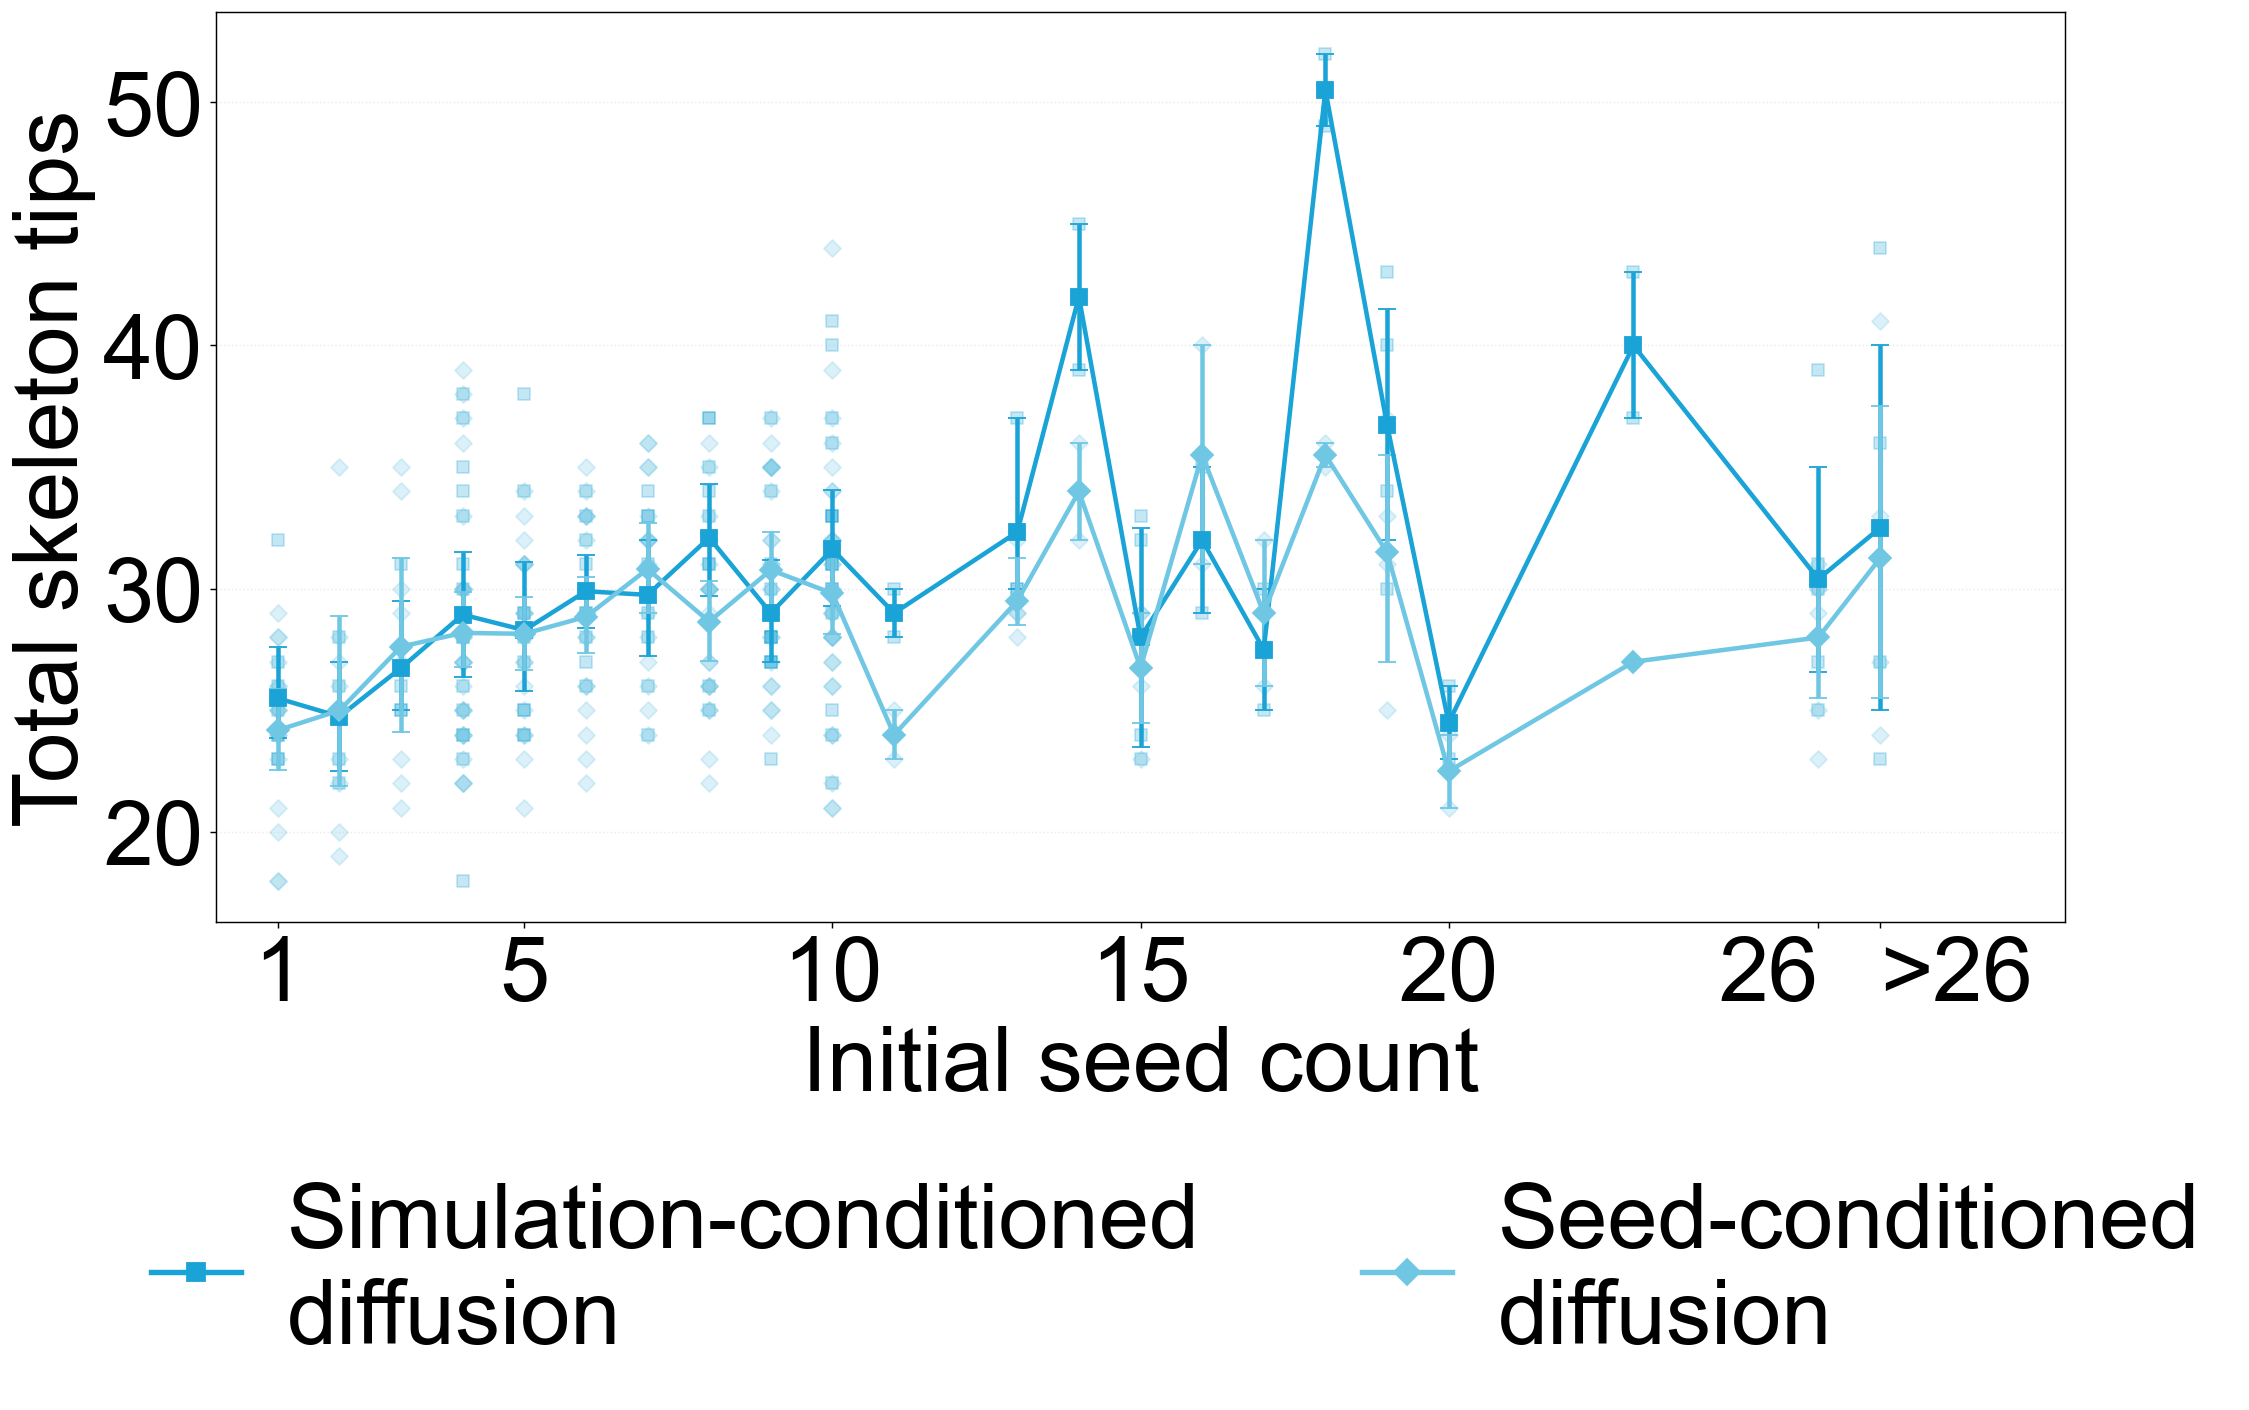

,source,metric,seed_count_plot,seed_count_group,actual_seed_count_min,actual_seed_count_max,plate_count,mean,sd,ci_lower,ci_upper
0,Simulation-conditioned diffusion,branch_tip_count,1,1,1,1,8,25.500000,2.976095,23.875000,27.625000
1,Simulation-conditioned diffusion,branch_tip_count,2,2,2,2,4,24.750000,2.753785,22.500000,27.000000
2,Simulation-conditioned diffusion,branch_tip_count,3,3,3,3,4,26.750000,2.872281,25.000000,29.500000
3,Simulation-conditioned diffusion,branch_tip_count,4,4,4,4,16,28.937500,5.543389,26.371875,31.500000
4,Simulation-conditioned diffusion,branch_tip_count,5,5,5,5,10,28.300000,4.571652,25.800000,31.100000
5,Simulation-conditioned diffusion,branch_tip_count,6,6,6,6,10,29.900000,2.601282,28.400000,31.400000
6,Simulation-conditioned diffusion,branch_tip_count,7,7,7,7,8,29.750000,3.615443,27.250000,32.000000
7,Simulation-conditioned diffusion,branch_tip_count,8,8,8,8,10,32.100000,4.094712,29.700000,34.300000
8,Simulation-conditioned diffusion,branch_tip_count,9,9,9,9,12,29.000000,3.643175,27.000000,31.168750
9,Simulation-conditioned diffusion,branch_tip_count,10,10,10,10,16,31.625000,5.289928,29.312500,34.064062


In [13]:
tips_by_seed_df = seed_count_summary('branch_tip_count')
fig, ax = plt.subplots(figsize=(18, 10))
for source in SOURCE_ORDER:
    plates = plate_df[plate_df['source'] == source]
    summary = tips_by_seed_df[tips_by_seed_df['source'] == source].sort_values('seed_count_plot')
    ax.scatter(plates['seed_count_plot'], plates['branch_tip_count'],
               color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
               s=45, alpha=0.25)
    plot_seed_count_summary(ax, summary, connect_overflow=True,
                color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
                linewidth=2.5, markersize=9, capsize=5)
configure_seed_count_axis(ax)
ax.set_xlabel('Initial seed count')
ax.set_ylabel('Total skeleton tips')
ax.grid(axis='y', linestyle=':', alpha=0.25)
fig.subplots_adjust(bottom=0.25)
fig.legend(
    handles=[
        plt.Line2D([], [], color=SOURCE_COLORS['Simulation-conditioned diffusion'],
                   marker=SOURCE_MARKERS['Simulation-conditioned diffusion'],
                   linewidth=3, markersize=10,
                   label='Simulation-conditioned\ndiffusion'),
        plt.Line2D([], [], color=SOURCE_COLORS['Seed-conditioned diffusion'],
                   marker=SOURCE_MARKERS['Seed-conditioned diffusion'],
                   linewidth=3, markersize=10,
                   label='Seed-conditioned\ndiffusion'),
    ],
    loc='lower center', ncol=2, bbox_to_anchor=(0.6, -0.15), frameon=False,
    prop={'family': plt.rcParams['font.family'][0], 'size': PLOT_FONT_SIZE},
    handlelength=1.0, handletextpad=0.5, columnspacing=1.8,
)
fig.subplots_adjust(left=0.19, right=0.98, top=0.95)
save_figure(fig, 'total_tips_vs_seed_count_simulation_vs_seed_conditioned')
plt.show()
display(tips_by_seed_df)


In [15]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: current Supp. Fig. 18F (conditioning tips)
from pathlib import Path
import runpy as _pdf_runpy
import matplotlib.pyplot as plt
PDF_PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'figure_exports').is_dir())
_pdf_helpers = vars(_figure_exports)
_save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
assert fig.axes[0].get_ylabel() == 'Total skeleton tips', \
    'Run the skeleton-tips plotting cell immediately before the S18F export.'
_save_vector_pdf(fig, PDF_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots' /
    'SuppFig18F_conditioning_tips_vs_seed_count.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18F_conditioning_tips_vs_seed_count.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18F_conditioning_tips_vs_seed_count.pdf')

## Total skeleton length versus initial seed count


The final **>26** category pools the 37- and 57-seed configurations; actual counts are retained separately.

The >26 mean/error-bar marker is connected to the preceding count group as a visual guide.

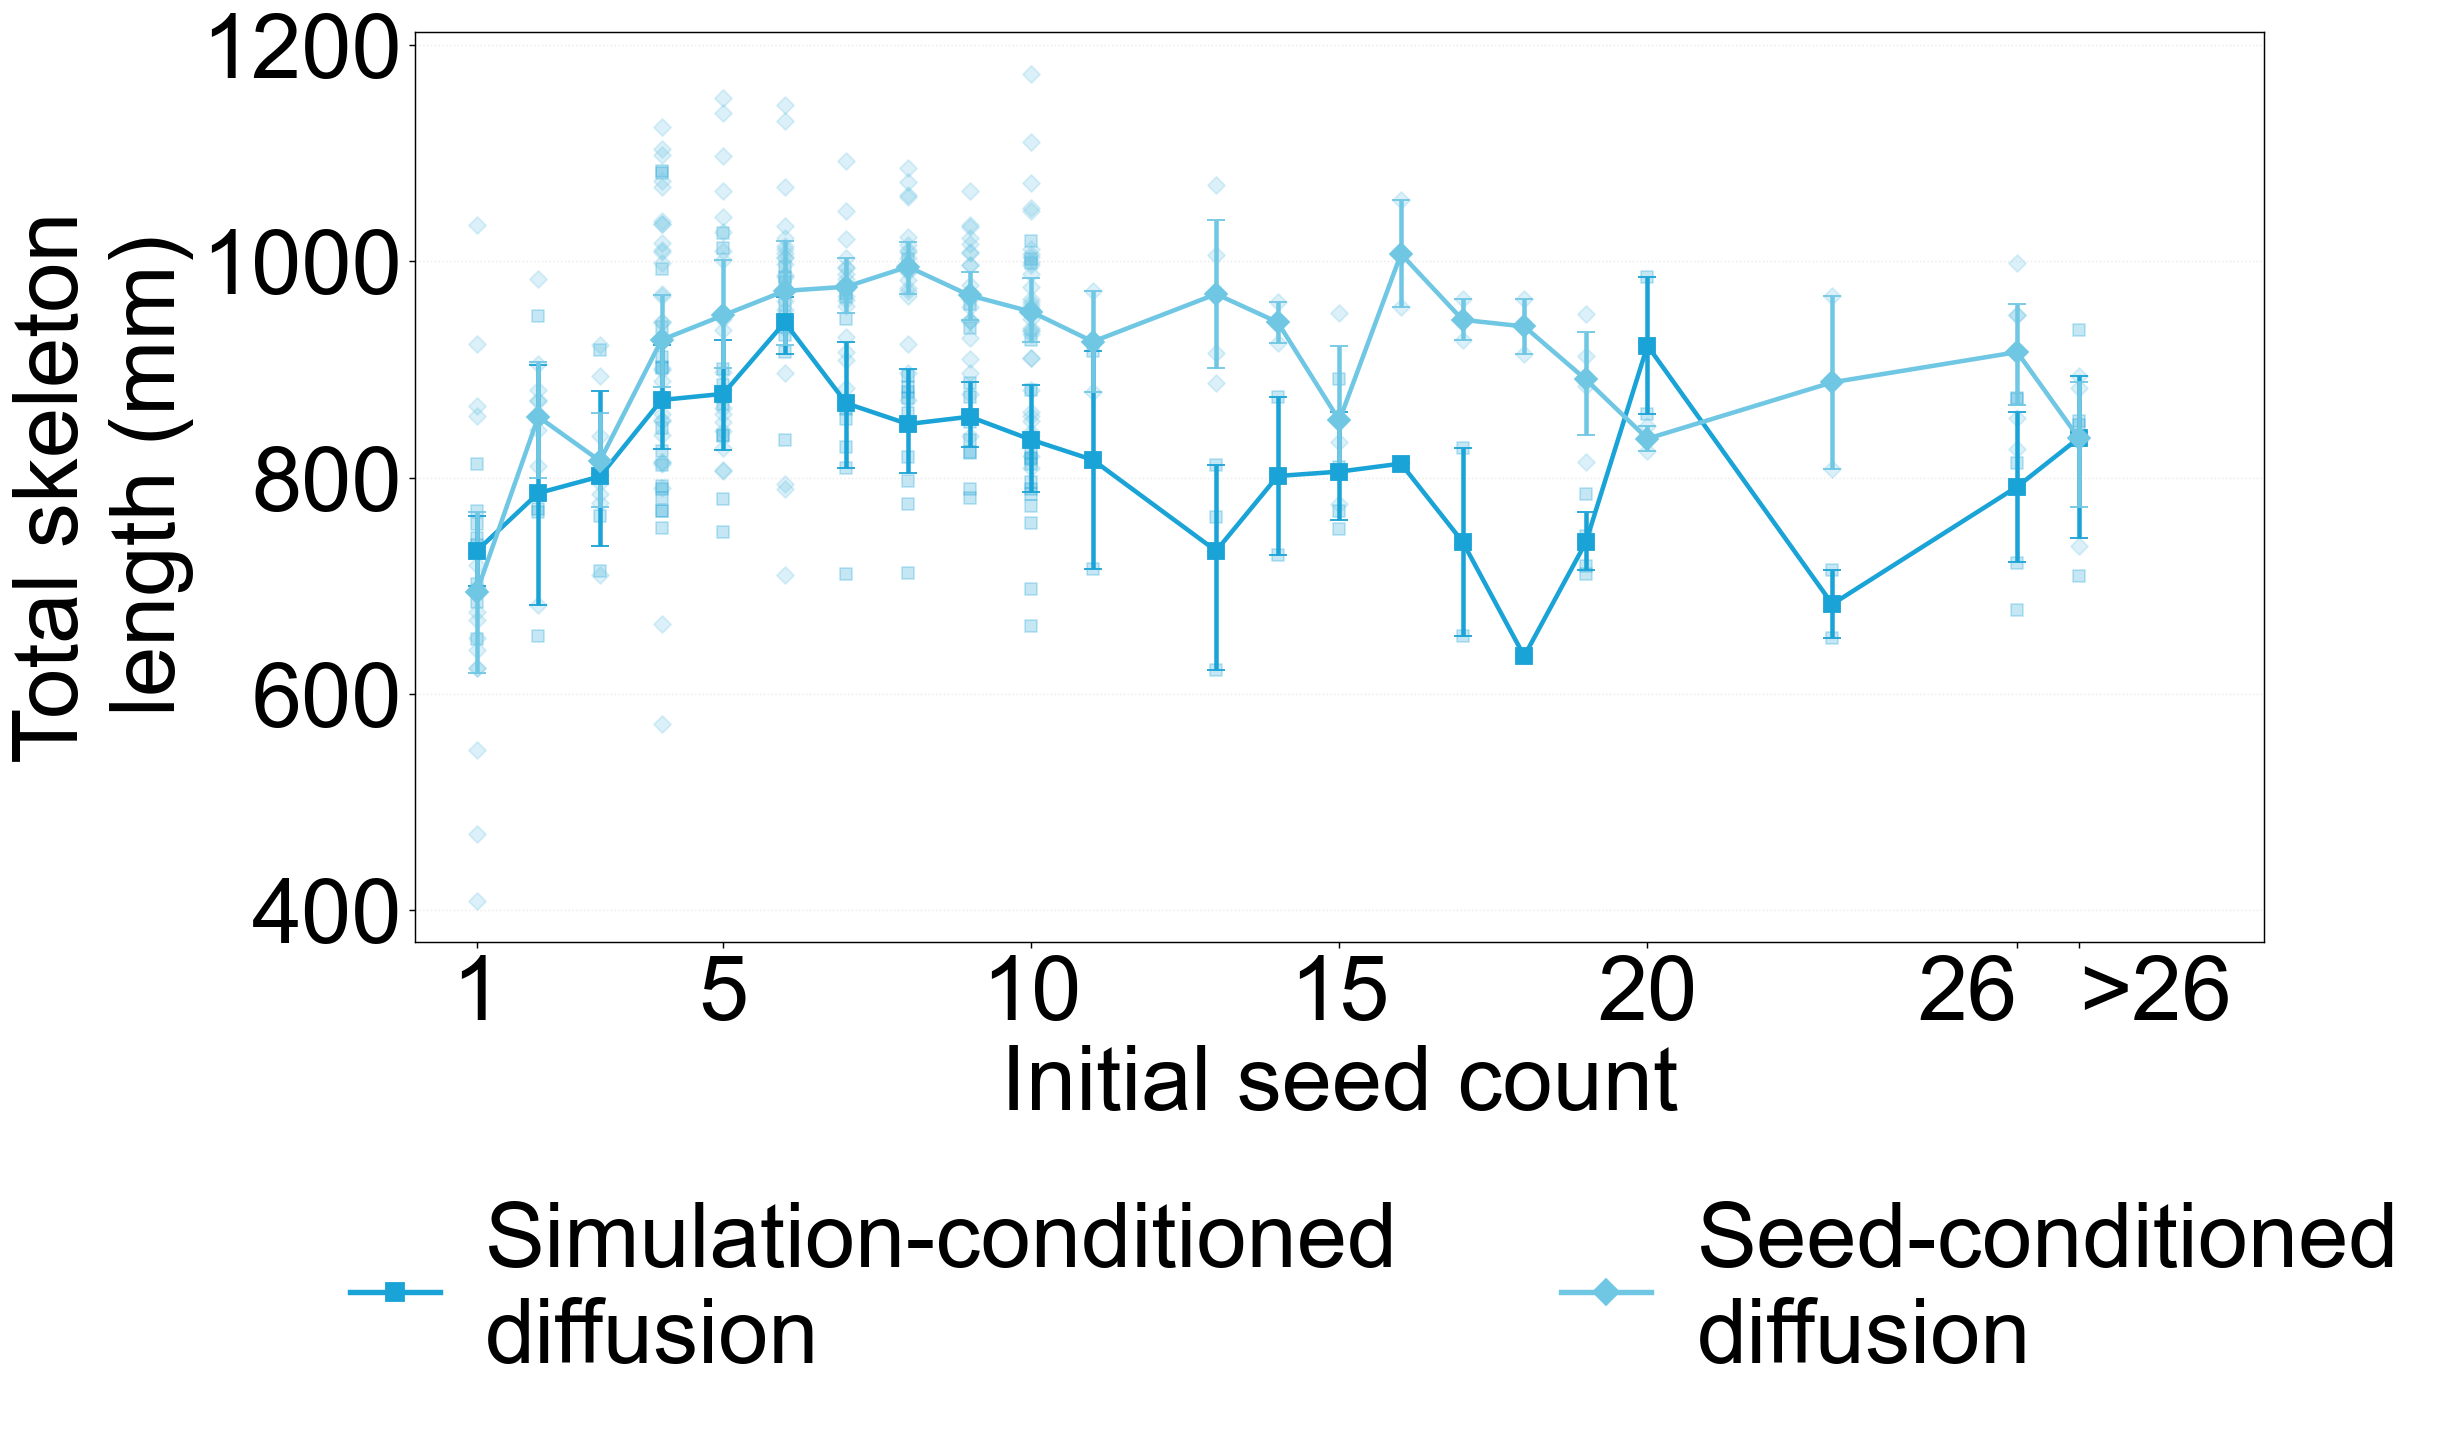

,source,metric,seed_count_plot,seed_count_group,actual_seed_count_min,actual_seed_count_max,plate_count,mean,sd,ci_lower,ci_upper
0,Simulation-conditioned diffusion,total_skeleton_length_plot,1,1,1,1,8,732.189878,51.137991,699.912092,764.635913
1,Simulation-conditioned diffusion,total_skeleton_length_plot,2,2,2,2,4,785.640514,122.345653,682.154276,904.338043
2,Simulation-conditioned diffusion,total_skeleton_length_plot,3,3,3,3,4,801.017978,87.232729,737.025874,879.938188
3,Simulation-conditioned diffusion,total_skeleton_length_plot,4,4,4,4,16,871.751444,107.786178,826.129346,922.979361
4,Simulation-conditioned diffusion,total_skeleton_length_plot,5,5,5,5,10,877.423819,88.116426,825.189524,927.467145
5,Simulation-conditioned diffusion,total_skeleton_length_plot,6,6,6,6,10,943.606804,45.782794,914.658920,966.689052
6,Simulation-conditioned diffusion,total_skeleton_length_plot,7,7,7,7,8,868.652289,89.973061,808.622037,925.236720
7,Simulation-conditioned diffusion,total_skeleton_length_plot,8,8,8,8,10,849.500483,79.063151,804.543534,900.601397
8,Simulation-conditioned diffusion,total_skeleton_length_plot,9,9,9,9,12,856.292117,53.588872,828.354485,888.049282
9,Simulation-conditioned diffusion,total_skeleton_length_plot,10,10,10,10,16,834.969284,104.808430,786.579154,885.632203


In [16]:
total_length_by_seed_df = seed_count_summary('total_skeleton_length_plot')
fig, ax = plt.subplots(figsize=(18, 10))
for source in SOURCE_ORDER:
    plates = plate_df[plate_df['source'] == source]
    summary = total_length_by_seed_df[
        total_length_by_seed_df['source'] == source
    ].sort_values('seed_count_plot')
    ax.scatter(plates['seed_count_plot'], plates['total_skeleton_length_plot'],
               color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
               s=45, alpha=0.25)
    plot_seed_count_summary(ax, summary, connect_overflow=True,
                color=SOURCE_COLORS[source], marker=SOURCE_MARKERS[source],
                linewidth=2.5, markersize=9, capsize=5)
configure_seed_count_axis(ax)
ax.set_xlabel('Initial seed count')
ax.set_ylabel(f'Total skeleton\n length ({LENGTH_UNIT})')
ax.grid(axis='y', linestyle=':', alpha=0.25)
fig.subplots_adjust(bottom=0.25)
fig.legend(
    handles=[
        plt.Line2D([], [], color=SOURCE_COLORS['Simulation-conditioned diffusion'],
                   marker=SOURCE_MARKERS['Simulation-conditioned diffusion'],
                   linewidth=3, markersize=10,
                   label='Simulation-conditioned\ndiffusion'),
        plt.Line2D([], [], color=SOURCE_COLORS['Seed-conditioned diffusion'],
                   marker=SOURCE_MARKERS['Seed-conditioned diffusion'],
                   linewidth=3, markersize=10,
                   label='Seed-conditioned\ndiffusion'),
    ],
    loc='lower center', ncol=2, bbox_to_anchor=(0.6, -0.15), frameon=False,
    prop={'family': plt.rcParams['font.family'][0], 'size': PLOT_FONT_SIZE},
    handlelength=1.0, handletextpad=0.5, columnspacing=1.8,
)
fig.subplots_adjust(left=0.19, right=0.98, top=0.95)
save_figure(fig, 'total_skeleton_length_vs_seed_count_simulation_vs_seed_conditioned')
plt.show()
display(total_length_by_seed_df)


In [18]:
from pathlib import Path as _ExportPath
import sys as _export_sys
_EXPORT_ROOT = next(p for p in (_ExportPath.cwd(), *_ExportPath.cwd().parents)
                    if (p / 'figure_exports').is_dir())
if str(_EXPORT_ROOT) not in _export_sys.path:
    _export_sys.path.insert(0, str(_EXPORT_ROOT))
import figure_exports as _figure_exports
# Vector PDF export: current Supp. Fig. 18E (conditioning length)
from pathlib import Path
import runpy as _pdf_runpy
import matplotlib.pyplot as plt
PDF_PROJECT_ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents)
                        if (p / 'figure_exports').is_dir())
_pdf_helpers = vars(_figure_exports)
_save_vector_pdf = vars(_figure_exports)['save_vector_pdf']
assert fig.axes[0].get_ylabel() == f'Total skeleton\n length ({LENGTH_UNIT})', \
    'Run the total-skeleton-length plotting cell immediately before the S18E export.'
_save_vector_pdf(fig, PDF_PROJECT_ROOT / 'sim_to_exp_diffusion' / 'vector based plots' /
    'SuppFig18E_conditioning_length_vs_seed_count.pdf')


Saved vector PDF: /hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18E_conditioning_length_vs_seed_count.pdf


PosixPath('/hpc/dctrl/ks723/Physics_constrained_DL_pattern_prediction/sim_to_exp_diffusion/vector based plots/SuppFig18E_conditioning_length_vs_seed_count.pdf')

## Optional table export

These tables retain the plate as the statistical unit and preserve individual terminal widths for auditing.

In [12]:
from pathlib import Path as _DataPath
import sys as _data_sys
_DATA_ROOT = next(p for p in (_DataPath.cwd(), *_DataPath.cwd().parents) if (p / 'paper_paths.py').is_file())
if str(_DATA_ROOT) not in _data_sys.path: _data_sys.path.insert(0, str(_DATA_ROOT))
from paper_paths import figure_source_path as _figure_source_path
if TABLE_OUTPUT_DIR is not None:
    output_directory = Path(TABLE_OUTPUT_DIR)
    output_directory.mkdir(parents=True, exist_ok=True)
    plate_df.to_csv(_figure_source_path(output_directory / 'plate_metrics_simulation_vs_seed_conditioned.csv'), index=False)
    terminal_width_df.to_csv(_figure_source_path(output_directory / 'terminal_widths_simulation_vs_seed_conditioned.csv'), index=False)
    width_distribution_df.to_csv(_figure_source_path(output_directory / 'terminal_width_kde_simulation_vs_seed_conditioned.csv'), index=False)
    width_cv_summary_df.to_csv(_figure_source_path(output_directory / 'width_cv_summary_simulation_vs_seed_conditioned.csv'), index=False)
    tips_by_seed_df.to_csv(_figure_source_path(output_directory / 'tips_by_seed_simulation_vs_seed_conditioned.csv'), index=False)
    total_length_by_seed_df.to_csv(_figure_source_path(output_directory / 'length_by_seed_simulation_vs_seed_conditioned.csv'), index=False)
    print(f'Wrote tables to {output_directory.resolve()}')